# Ứng dụng 1 — Phân tích giỏ hàng (Market Basket Analysis)

Ứng dụng thuộc Chương 3 của đồ án cài đặt lại thuật toán FPClose. Mục tiêu là tìm các nhóm sản phẩm thường được mua cùng nhau trong một cửa hàng bán lẻ trực tuyến, từ đó sinh các luật kết hợp (association rules) $X \rightarrow Y$, trong đó support của $X$ đạt ngưỡng minsup và confidence của luật đạt ngưỡng minconf. Top-10 luật theo lift được trình bày cùng diễn giải ý nghĩa kinh doanh.

Toàn bộ tập phổ biến và luật kết hợp được sinh bằng chính cài đặt FPClose của nhóm (dòng lệnh `demo.jl` hoặc các hàm trong `src/`); nhóm không sử dụng mlxtend hay bất kỳ thư viện khai thác tập phổ biến nào khác. Các thư viện Python (pandas, openpyxl, matplotlib) chỉ đảm nhận việc đọc dữ liệu, biến đổi dữ liệu thành giao dịch và trình bày kết quả. Mã tiền xử lý nằm trong `applications/application_01/market_basket.py`.

**Dữ liệu.** UCI Online Retail (id 352): các giao dịch của một cửa hàng bán lẻ trực tuyến tại Vương quốc Anh trong giai đoạn 12/2010–12/2011, gồm các cột InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country. Giấy phép CC BY 4.0.

> Chen, D. (2015). *Online Retail* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5BW33

**Nội dung:**
1. Môi trường thực thi
2. Cấu hình
3. Tiền xử lý dữ liệu: (3.1) tải và đọc dữ liệu; (3.2) chẩn đoán; (3.3) làm sạch; (3.4) biến đổi thành giao dịch và ghi file SPMF; (3.5) thống kê giao dịch
4. Khai thác tập phổ biến đóng
5. Khảo sát ngưỡng minsup
6. Sinh luật kết hợp
7. Top-10 luật theo lift
8. Diễn giải ý nghĩa kinh doanh

## 1. Môi trường thực thi

Notebook sử dụng kernel Python 3. Khi chạy trên Google Colab (nhận biết qua sự tồn tại của thư mục `/content`), ô dưới đây tải mã nguồn của repository vào `/content/FPClose` theo nhánh `BRANCH`; khi chạy local, gốc repository được xác định là thư mục cha gần nhất chứa `Project.toml`. Ở giai đoạn tiền xử lý, notebook chỉ cần mã Python của repository; việc cài đặt Julia và `Pkg.instantiate()` được bổ sung ở bước khai thác tập phổ biến đóng.

Các thư viện Python cần thiết gồm `pandas`, `openpyxl` (đọc file xlsx) và `matplotlib` (vẽ hình); thư viện nào chưa có sẽ được cài bằng `pip`. Sau đó thư mục `applications/application_01` được thêm vào `sys.path` để nạp module `market_basket`.

In [1]:
import os, sys, subprocess, importlib, importlib.util
from pathlib import Path

REPO_URL = 'https://github.com/DRAGON-1312/FPClose.git'
BRANCH = 'feature/app1-market-basket'   # nhánh mã nguồn dùng khi chạy trên Colab
REPO_DIR = '/content/FPClose'
IN_COLAB = os.path.isdir('/content')

if IN_COLAB:
    # Giai đoạn tiền xử lý chỉ cần mã Python của repo; cài Julia + Pkg.instantiate bổ sung ở bước khai thác.
    if not os.path.isdir(os.path.join(REPO_DIR, '.git')):
        subprocess.run(['git', 'clone', '--quiet', REPO_URL, REPO_DIR], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'fetch', '--quiet', 'origin', BRANCH], check=True)
    subprocess.run(['git', '-C', REPO_DIR, 'checkout', '--quiet', '-B', BRANCH, 'FETCH_HEAD'], check=True)
    repo = Path(REPO_DIR)
else:
    repo = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / 'Project.toml').is_file())

for pkg in ('pandas', 'openpyxl', 'matplotlib'):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

app_path = str(repo / 'applications' / 'application_01')
if app_path not in sys.path:
    sys.path.insert(0, app_path)
import market_basket as mb
mb = importlib.reload(mb)   # nạp lại khi module được sửa trong lúc chạy notebook
ROOT = mb.find_root()
print('Gốc repository:', ROOT, '| Colab:', IN_COLAB)

Gốc repository: C:\HCMUS\Data Mining\FPClose\FPClose | Colab: False


## 2. Cấu hình

Mọi tham số có ảnh hưởng đến kết quả được khai báo tập trung tại ô dưới đây: nguồn dữ liệu và mã băm SHA-256 của file gốc, danh sách mã không phải sản phẩm (`NON_PRODUCT`) cùng các tiền tố tương ứng, mẫu StockCode dùng cho thống kê và id của item đầu tiên. Giá trị mặc định được nạp từ module `market_basket` và có thể được điều chỉnh trực tiếp tại đây. `HF_URL` là địa chỉ bản sao trên Hugging Face (nếu có); khi để trống, dữ liệu được tải trực tiếp từ UCI.

In [2]:
import pandas as pd
from IPython.display import Image, display

APP = ROOT / 'applications' / 'application_01'
UCI_URL = 'https://archive.ics.uci.edu/static/public/352/online+retail.zip'
HF_URL = ''                                   # bản sao trên Hugging Face (nếu có)
SHA256 = '43465A06F2CCF7C8B5BD2892BC7DEFB52F97487934FE93B16AE4C3936424676D'
NON_PRODUCT = mb.NON_PRODUCT                  # mã không phải sản phẩm (so sau strip().upper())
NON_PRODUCT_PREFIXES = mb.NON_PRODUCT_PREFIXES  # tiền tố mã không phải sản phẩm
STOCK_CODE_PATTERN = mb.STOCK_CODE_PATTERN    # chỉ dùng để thống kê mã lệch mẫu, không dùng để loại
ID_START = mb.ID_START                        # id item đầu tiên (read_spmf nhận id >= 0)

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)
print('Thư mục ứng dụng:', APP)
print('NON_PRODUCT:', NON_PRODUCT, '| tiền tố:', NON_PRODUCT_PREFIXES, '| ID_START:', ID_START)

Thư mục ứng dụng: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01
NON_PRODUCT: ('POST', 'DOT', 'M', 'D', 'C2', 'CRUK', 'PADS', 'S', 'B', 'BANK CHARGES', 'AMAZONFEE') | tiền tố: ('GIFT_', 'DCGS') | ID_START: 1


## 3. Tiền xử lý dữ liệu

Mỗi giao dịch được định nghĩa là một hóa đơn (InvoiceNo) và mỗi item là một mã sản phẩm (StockCode). Phần này trình bày lần lượt các quyết định biến đổi dữ liệu gốc thành giao dịch, theo đúng định dạng đầu vào của cài đặt FPClose của nhóm.

### 3.1 Tải và đọc dữ liệu

File gốc `Online Retail.xlsx` được lưu tại `applications/application_01/data/raw/`. Khi file chưa tồn tại, dữ liệu được tải từ `HF_URL` (nếu có) hoặc từ gói zip của UCI. Mã băm SHA-256 của file được so với giá trị khai báo ở mục 2 nhằm bảo đảm mọi lần chạy đều sử dụng cùng một phiên bản dữ liệu. Các cột InvoiceNo, StockCode và Description được đọc dưới dạng chuỗi để giữ nguyên các mã có chữ cái (ví dụ hóa đơn hủy bắt đầu bằng 'C', mã sản phẩm có hậu tố chữ). Kết quả đọc được lưu cache dạng pickle, gắn với mã băm của file gốc; khi mã băm thay đổi, dữ liệu được đọc lại từ file xlsx.

In [3]:
df_raw = mb.load_raw(APP, UCI_URL, SHA256, hf_url=HF_URL)
print(f'{len(df_raw):,} dòng, {df_raw.shape[1]} cột')
display(df_raw.head())

541,909 dòng, 8 cột


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**Kết quả.** Dữ liệu gồm 541.909 dòng và 8 cột; mã băm SHA-256 của file khớp với giá trị khai báo. Mỗi dòng tương ứng với một sản phẩm trong một hóa đơn, do đó dữ liệu cần được gom theo InvoiceNo để tạo thành giao dịch.

### 3.2 Chẩn đoán dữ liệu

Trước khi loại bỏ bất kỳ dòng nào, dữ liệu được chẩn đoán để định lượng các vấn đề có thể ảnh hưởng đến giao dịch: hóa đơn hủy (InvoiceNo bắt đầu bằng 'C' hoặc 'c'), số lượng hoặc đơn giá không dương, mô tả rỗng, InvoiceNo hoặc StockCode thiếu, và CustomerID thiếu. StockCode được chuẩn hóa bằng `strip().upper()` trước khi đối chiếu với mẫu `^\d{5}[A-Z]{0,2}$` của một mã sản phẩm thông thường; mọi mã lệch mẫu được liệt kê kèm mô tả phổ biến nhất và số dòng, làm căn cứ xây dựng danh sách mã không phải sản phẩm. Các mã có nhiều mô tả khác nhau cũng được thống kê, vì tên hiển thị của mỗi sản phẩm cần được chọn theo một quy tắc tất định.

In [4]:
diagnosis = mb.diagnose(df_raw, pattern=STOCK_CODE_PATTERN)
for name, table in diagnosis.items():
    print('==', name)
    display(table)

== summary


,chỉ số,số lượng
0,Tổng số dòng,541909
1,Số hóa đơn phân biệt,25900
2,Số hóa đơn hủy (InvoiceNo bắt đầu bằng 'C'/'c'),3836
3,Số dòng thuộc hóa đơn hủy,9288
4,Số dòng Quantity <= 0 hoặc thiếu,10624
5,Số dòng UnitPrice <= 0 hoặc thiếu,2517
6,Số dòng Description rỗng,1454
7,Số dòng InvoiceNo thiếu/rỗng,0
8,Số dòng StockCode thiếu/rỗng,0
9,Số dòng thiếu CustomerID (không loại),135080


== irregular_codes


,stock_code,description,n_rows
0,POST,POSTAGE,1256
1,DOT,DOTCOM POSTAGE,710
2,M,Manual,572
3,C2,CARRIAGE,144
4,D,Discount,77
5,S,SAMPLES,63
6,BANK CHARGES,Bank Charges,37
7,AMAZONFEE,AMAZON FEE,34
8,CRUK,CRUK Commission,16
9,DCGSSGIRL,GIRLS PARTY BAG,13


== multi_description


,stock_code,n_descriptions,descriptions
0,20713,8,Found | JUMBO BAG OWLS | Marked as 23343 | found | wrongly coded 23343 | wrongly coded-23343 | w...
1,23084,7,Amazon | RABBIT NIGHT LIGHT | add stock to allocate online orders | allocate stock for dotcom or...
2,21830,6,"? | ASSORTED CREEPY CRAWLIES | MERCHANT CHANDLER CREDIT ERROR, STO | OOPS ! adjustment | damaged..."
3,85175,6,? sold as sets? | Amazon sold sets | CACTI T-LIGHT CANDLES | check | dotcom sold sets | wrongly ...
4,21181,5,PLEASE ONE PERSON METAL SIGN | adjustment | check | dotcom | on cargo order


**Kết quả.** Dữ liệu gồm 25.900 hóa đơn, trong đó 3.836 hóa đơn hủy (9.288 dòng). Có 135.080 dòng (khoảng 24,9%) thiếu CustomerID; các dòng này được giữ lại vì giao dịch của khách vãng lai vẫn là hóa đơn hợp lệ. Toàn bộ 32 StockCode lệch mẫu thuộc các nhóm không phải hàng hóa: phí vận chuyển (POST, DOT, C2), điều chỉnh kế toán (M, D, B, BANK CHARGES, AMAZONFEE, CRUK), hàng mẫu (S), phiếu quà tặng (GIFT_*) và mã của kênh bán riêng (DCGS*). Danh sách `NON_PRODUCT` cùng hai tiền tố bao phủ đủ 32 mã này. Một số mã DCGS* và PADS có mô tả giống sản phẩm, nhưng mỗi mã xuất hiện không quá 13 dòng, thấp hơn nhiều so với ngưỡng support được khảo sát (≥ 1%, tương đương khoảng 198 hóa đơn), nên việc loại các mã này không ảnh hưởng đến kết quả khai thác. 638 mã có nhiều hơn một mô tả, chủ yếu do các ghi chú điều chỉnh kho ("damaged", "wrongly coded", "?"); quy tắc chọn mô tả xuất hiện nhiều nhất bảo đảm tên hiển thị là tên sản phẩm.

### 3.3 Làm sạch dữ liệu

Các bước làm sạch được áp dụng theo một thứ tự cố định, mỗi bước tác động lên kết quả của bước trước: (1) loại dòng thiếu InvoiceNo hoặc StockCode; (2) loại hóa đơn hủy; (3) loại dòng có Quantity ≤ 0; (4) loại dòng có UnitPrice ≤ 0; (5) loại dòng có Description rỗng; (6) loại các mã không phải sản phẩm, gồm các mã thuộc `NON_PRODUCT` và các mã bắt đầu bằng tiền tố `GIFT_` hoặc `DCGS`. Các mã lệch mẫu còn lại không bị loại tự động mà chỉ được thống kê ở mục 3.2. Dòng thiếu CustomerID được giữ lại, vì giao dịch của khách vãng lai vẫn là một hóa đơn hợp lệ. Bảng dưới đây ghi nhận số dòng bị loại và số dòng còn lại sau từng bước.

In [5]:
df_clean, cleaning_steps = mb.clean(df_raw, non_product=NON_PRODUCT, prefixes=NON_PRODUCT_PREFIXES)
display(cleaning_steps)

,bước,mô tả,số dòng bị loại,số dòng còn lại
0,0,Dữ liệu gốc,0,541909
1,1,InvoiceNo hoặc StockCode thiếu/rỗng,0,541909
2,2,Hóa đơn hủy (InvoiceNo bắt đầu bằng 'C'/'c'),9288,532621
3,3,Quantity <= 0 hoặc thiếu,1336,531285
4,4,UnitPrice <= 0 hoặc thiếu,1181,530104
5,5,Description rỗng,0,530104
6,6,"Mã không phải sản phẩm (AMAZONFEE, B, BANK CHARGES, C2, CRUK, D, DOT, M, PADS, POST, S; tiền tố ...",2379,527725


**Kết quả.** Sau làm sạch còn 527.725 dòng (97,4% dữ liệu gốc). Hóa đơn hủy chiếm phần lớn số dòng bị loại (9.288 dòng). Ngoài hóa đơn hủy còn 1.336 dòng có số lượng không dương và 1.181 dòng có đơn giá không dương, phần lớn là điều chỉnh kho hoặc hàng tặng. Bước loại mô tả rỗng không loại thêm dòng nào: toàn bộ 1.454 dòng thiếu mô tả đã bị loại ở các bước trước, do đều có số lượng hoặc đơn giá không dương. Bước cuối loại 2.379 dòng thuộc mã không phải sản phẩm.

### 3.4 Biến đổi thành giao dịch và ghi file SPMF

Mỗi giao dịch là tập các StockCode phân biệt xuất hiện trong một hóa đơn: thông tin số lượng (Quantity) không được sử dụng, các dòng trùng mã trong cùng một hóa đơn được gộp lại, và các hóa đơn chỉ gồm một sản phẩm vẫn được giữ. Mỗi StockCode được ánh xạ sang một id nguyên dương liên tục bắt đầu từ `ID_START`, theo thứ tự tăng dần của mã; `read_spmf` của nhóm chấp nhận mọi id ≥ 0, và việc bắt đầu từ 1 giúp giữ cùng quy ước với các file benchmark và với SPMF. Tên hiển thị của mỗi sản phẩm là Description xuất hiện nhiều nhất của mã đó; khi hòa, chuỗi nhỏ nhất theo thứ tự từ điển được chọn.

Giao dịch được ghi vào `data/transactions.txt` theo thứ tự InvoiceNo, mỗi dòng gồm các id tăng dần cách nhau bởi dấu cách. Bảng ánh xạ `data/item_map.csv` gồm id, stock_code, description, n_transactions (số hóa đơn chứa sản phẩm) và support_pct (tỷ lệ phần trăm hóa đơn chứa sản phẩm). Sau khi ghi, file được đọc lại để kiểm tra: số dòng bằng số giao dịch, không có dòng rỗng, không có item trùng trong một dòng, item tăng dần và tập item trong file trùng với tập id của bảng ánh xạ.

In [6]:
transactions, item_map, tx_info = mb.to_transactions(df_clean, id_start=ID_START)
print(tx_info)
display(item_map.head(10))

{'n_rows': 527725, 'n_duplicate_rows_merged': 10471, 'n_transactions': 19773, 'n_items': 3791, 'id_start': 1}


,id,stock_code,description,n_transactions,support_pct
0,1,10002,INFLATABLE POLITICAL GLOBE,71,0.359076
1,2,10080,GROOVY CACTUS INFLATABLE,22,0.111263
2,3,10120,DOGGY RUBBER,29,0.146665
3,4,10123C,HEARTS WRAPPING TAPE,3,0.015172
4,5,10124A,SPOTS ON RED BOOKCOVER TAPE,5,0.025287
5,6,10124G,ARMY CAMO BOOKCOVER TAPE,4,0.020230
6,7,10125,MINI FUNKY DESIGN TAPES,91,0.460224
7,8,10133,COLOURING PENCILS BROWN TUBE,196,0.991251
8,9,10135,COLOURING PENCILS BROWN TUBE,175,0.885045
9,10,11001,ASSTD DESIGN RACING CAR PEN,113,0.571486


In [7]:
spmf_files = mb.write_spmf(transactions, item_map, APP, id_start=ID_START)
for name, path in spmf_files.items():
    print(f'{name}: {path}')

transactions: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\data\transactions.txt
item_map: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\data\item_map.csv


**Kết quả.** 10.471 dòng trùng mã trong cùng một hóa đơn được gộp, tạo thành 19.773 giao dịch trên 3.791 item (id từ 1 đến 3.791). Số giao dịch nhỏ hơn số hóa đơn không bị hủy (22.064), vì 2.291 hóa đơn chỉ gồm các dòng đã bị loại (phí, điều chỉnh, hàng có đơn giá bằng 0) nên không còn sản phẩm nào. File `transactions.txt` vượt qua mọi kiểm tra sau khi ghi. Một số mã khác nhau có cùng mô tả (ví dụ 10133 và 10135), vì vậy các bảng kết quả ở phần sau hiển thị tên sản phẩm kèm StockCode.

### 3.5 Thống kê giao dịch

Các đặc trưng của tập giao dịch được tổng hợp nhằm làm cơ sở cho việc chọn ngưỡng minsup ở các bước sau: số giao dịch, số item, độ dài giỏ hàng (trung bình, trung vị, phân vị 90 và lớn nhất), tỷ lệ hóa đơn chỉ gồm một sản phẩm và mật độ dữ liệu (độ dài trung bình chia cho số item). Mười sản phẩm có support cao nhất cho biết mức support tối đa mà một tập phổ biến có thể đạt. Phân bố độ dài giỏ hàng được biểu diễn bằng histogram, cắt tại phân vị 99 để phần đuôi dài không làm mất chi tiết của phần chính. Bảng thống kê, bảng các bước làm sạch và hình histogram được lưu vào `applications/application_01/results/` để sử dụng trong báo cáo.

In [8]:
tx_stats, top10_items = mb.transaction_stats(transactions, item_map)
display(tx_stats)
display(top10_items)

,chỉ số,giá trị
0,Số giao dịch (hóa đơn),19773.000
1,Số item (sản phẩm),3791.000
2,Độ dài giỏ trung bình,26.160
3,Độ dài giỏ trung vị,15.000
4,Độ dài giỏ p90,52.000
5,Độ dài giỏ lớn nhất,1106.000
6,Tỷ lệ hóa đơn 1 sản phẩm (%),7.586
7,Mật độ (%) = độ dài TB / số item,0.690


,id,stock_code,description,n_transactions,support_pct
0,3310,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2265,11.455014
1,3294,85099B,JUMBO BAG RED RETROSPOT,2089,10.564912
2,1306,22423,REGENCY CAKESTAND 3 TIER,1988,10.054114
3,2659,47566,PARTY BUNTING,1685,8.521722
4,171,20725,LUNCH BAG RED RETROSPOT,1565,7.914833
5,3131,84879,ASSORTED COLOUR BIRD ORNAMENT,1455,7.358519
6,1105,22197,POPCORN HOLDER,1392,7.039903
7,1589,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1385,7.004501
8,435,21212,PACK OF 72 RETROSPOT CAKE CASES,1320,6.675770
9,1272,22383,LUNCH BAG SUKI DESIGN,1284,6.493704


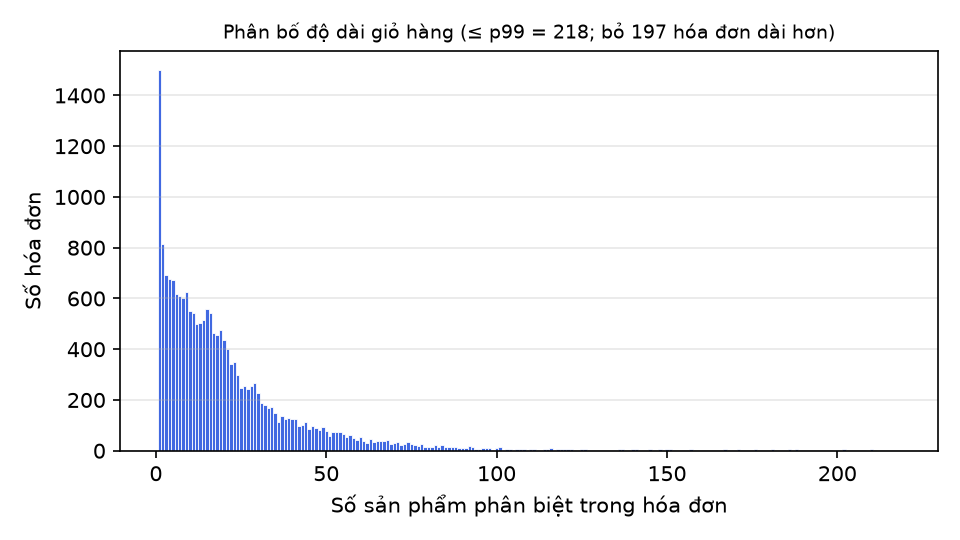

In [9]:
fig_path = mb.plot_basket_length(transactions, APP / 'results' / 'figures' / 'basket_length.png')
display(Image(filename=str(fig_path)))

In [10]:
saved = mb.save_results(APP, cleaning_steps, tx_stats)
for name, path in saved.items():
    print(f'{name}: {path}')

cleaning_steps: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\results\cleaning_steps.csv
transaction_stats: C:\HCMUS\Data Mining\FPClose\FPClose\applications\application_01\results\transaction_stats.csv


**Kết quả.** Độ dài giỏ hàng có trung bình 26,2, trung vị 15, phân vị 90 là 52 và lớn nhất 1.106 sản phẩm. Phân bố lệch phải rõ rệt do một số hóa đơn của khách mua sỉ, phù hợp với mô tả của bộ dữ liệu rằng nhiều khách hàng là người bán buôn. Các hóa đơn lớn được giữ nguyên, vì chúng phản ánh hành vi mua hàng thực tế của cửa hàng; do đó các luật tìm được cần được hiểu là hành vi mua của khách hàng doanh nghiệp, không chỉ của người tiêu dùng cá nhân. Hóa đơn chỉ gồm một sản phẩm chiếm 7,6%. Mật độ dữ liệu chỉ 0,69%: đây là dữ liệu rất thưa, tương tự Retail và Kosarak ở Chương 2. Sản phẩm phổ biến nhất (WHITE HANGING HEART T-LIGHT HOLDER) có support 11,5%, nên mọi ngưỡng minsup trên 11,5% đều không cho tập phổ biến nào; ngưỡng minsup được khảo sát trong khoảng 1%–3% ở mục 5.

## 4. Khai thác tập phổ biến đóng

*Được bổ sung ở bước tiếp theo.*

## 5. Khảo sát ngưỡng minsup

*Được bổ sung ở bước tiếp theo.*

## 6. Sinh luật kết hợp

*Được bổ sung ở bước tiếp theo.*

## 7. Top-10 luật theo lift

*Được bổ sung ở bước tiếp theo.*

## 8. Diễn giải ý nghĩa kinh doanh

*Được bổ sung ở bước tiếp theo.*